# Lecture 8 notebook: Filters and overlays

Companion to Lecture 8 of *Systematic Trading Notes*. Four filters, one per source of information and one per action,
applied to the same base system and judged by one common test: at equal speed, after costs, and by what they add to
the unfiltered system. Data: the 16 ETFs of Lectures 5 to 9, daily, 2000–2026; FRED series for the 3-month Treasury bill
and the VIX. Every input is lagged by one day, so that no filter uses information it would not have had.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display
from plotly.subplots import make_subplots

from trading_models.data.ohlc import load_ohlc
from trading_models.plotting import MUTED, SERIES, apply_theme, save_figure

apply_theme()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW = ROOT / "data" / "raw"
FIG = ROOT / "lectures" / "08-filters-and-overlays" / "figures"
TICKERS = ["SPY", "QQQ", "IWM", "EFA", "EEM", "XLE", "XLF", "XLK", "XLU", "VNQ", "AGG", "TLT", "GLD", "SLV", "GDX", "USO"]
C = load_ohlc(TICKERS, start="1993-01-01", cache=RAW / "nb05_ohlc.csv")["close"][TICKERS]
r = np.log(C).diff()
vol = r.ewm(span=60, min_periods=60).std()
TARGET = 0.10 / np.sqrt(252)
START = "2001-01-01"
idx = C.index


def fred(name):
    s = pd.read_csv(RAW / f"fred_{name}.csv", parse_dates=["observation_date"], index_col="observation_date").iloc[:, 0]
    return pd.to_numeric(s, errors="coerce").reindex(idx).ffill(limit=30).shift(1)   # known the next day


tbill, vix = fred("DTB3"), fred("VIXCLS")


def run(sig):
    pos = sig * TARGET / vol
    port = (pos.shift(1) * r).mean(axis=1).loc[START:]
    to = pos.diff().abs().mean(axis=1).loc[START:]
    return port, to


def metrics(port, to):
    cum = port.cumsum()
    out = {"turnover per year": 252 * to.mean(), "Sharpe, no costs": np.sqrt(252) * port.mean() / port.std()}
    net = port - to * 5 / 1e4
    out["Sharpe, 5 bp"] = np.sqrt(252) * net.mean() / net.std()
    out["max drawdown %"] = 100 * (cum - cum.cummax()).min()
    return out

## 3. The yardstick: the unfiltered rule at every speed (Table 3.1)

Time-series momentum at several lookbacks. A filter changes how often the system trades, so it must beat this curve
at its own turnover, not just the 12-month rule it was applied to.

In [2]:
sign = {n: np.sign(np.log(C).diff(n)) for n in (42, 63, 126, 189, 252, 378)}
curve = pd.DataFrame({n: metrics(*run(s)) for n, s in sign.items()}).T
curve.index.name = "lookback (days)"
display(curve.round(2))
base_sig = sign[252]
base_port, base_to = run(base_sig)
cs = curve.sort_values("turnover per year")


def on_curve(turnover, col):
    return float(np.interp(turnover, cs["turnover per year"], cs[col]))

,turnover per year,"Sharpe, no costs","Sharpe, 5 bp",max drawdown %
lookback (days),,,,
42,24.44,0.45,0.21,-10.54
63,19.44,0.32,0.14,-11.13
126,13.98,0.53,0.40,-10.53
189,11.00,0.59,0.48,-10.60
252,10.00,0.60,0.51,-13.63
378,8.06,0.46,0.39,-16.85


## 4. Four filters on the 12-month rule (Table 4.1)

| Filter | Source | Action | Rule |
|---|---|---|---|
| Efficiency-ratio gate | Price | Gate | Hold the position only while the asset's 63-day efficiency ratio exceeds a threshold; flat otherwise |
| Correlation scale | Cross-market | Scale | Halve every position while the average pairwise 63-day correlation of the 16 ETFs is above its median to date |
| Zero-rate regime | Macro | Restrict direction | No short positions while the 3-month Treasury bill yields below 0.25% |
| VIX regime | Implied volatility | Switch speed | Use the 3-month signal while the VIX is above its median to date, the 12-month signal otherwise |

In [3]:
lp = np.log(C)
er = (lp.diff(63).abs() / lp.diff().abs().rolling(63).sum()).shift(1)
rho_rows = r.rolling(63).corr()
avg_rho = rho_rows.groupby(level=0).apply(lambda m: (m.values[~np.eye(len(m), dtype=bool)]).mean() if m.notna().values.sum() > 30 else np.nan)
avg_rho = pd.Series(avg_rho, index=idx).shift(1)
rho_med = avg_rho.expanding(252).median()
vix_med = vix.expanding(252).median()

filters = {}
for th in (0.1, 0.2, 0.3):
    filters[f"efficiency-ratio gate, threshold {th}"] = base_sig.where(er > th, 0.0)
scale = pd.Series(np.where(avg_rho > rho_med, 0.5, 1.0), idx)
filters["correlation scale, halve above median"] = base_sig.mul(scale, axis=0)
zero = (tbill < 0.25)
filters["zero-rate regime, no shorts"] = base_sig.where(~(zero.values[:, None] & (base_sig < 0).values), 0.0)
hi_vix = (vix > vix_med)
hv = pd.DataFrame(np.repeat(hi_vix.values[:, None], len(TICKERS), axis=1), index=idx, columns=TICKERS)
filters["VIX regime, fast signal when high"] = sign[63].where(hv, base_sig)

rows = {"unfiltered 12-month rule": {**metrics(base_port, base_to)}}
for k, s in filters.items():
    p, t = run(s)
    m = metrics(p, t)
    m["curve Sharpe at same turnover, no costs"] = on_curve(m["turnover per year"], "Sharpe, no costs")
    m["curve Sharpe at same turnover, 5 bp"] = on_curve(m["turnover per year"], "Sharpe, 5 bp")
    d = pd.concat([p, base_port], axis=1, keys=["f", "b"]).dropna()
    X = np.column_stack([np.ones(len(d)), d.b])
    beta = np.linalg.lstsq(X, d.f, rcond=None)[0]
    e = d.f - X @ beta
    se = np.sqrt(np.diag(e @ e / (len(d) - 2) * np.linalg.inv(X.T @ X)))
    m["correlation with unfiltered"] = d.corr().iloc[0, 1]
    m["alpha over unfiltered, % a year"] = 100 * 252 * beta[0]
    m["t(alpha)"] = beta[0] / se[0]
    rows[k] = m
table = pd.DataFrame(rows).T
pd.set_option("display.width", 250)
display(table.round(2))
print("share of days each filter was active:")
print({"ER>0.2 (avg across assets)": round(float((er > 0.2).loc[START:].mean().mean()), 2),
       "correlation above median": round(float((avg_rho > rho_med).loc[START:].mean()), 2),
       "zero rates": round(float(zero.loc[START:].mean()), 2), "VIX above median": round(float(hi_vix.loc[START:].mean()), 2)})

,turnover per year,"Sharpe, no costs","Sharpe, 5 bp",max drawdown %,"curve Sharpe at same turnover, no costs","curve Sharpe at same turnover, 5 bp",correlation with unfiltered,"alpha over unfiltered, % a year",t(alpha)
unfiltered 12-month rule,10.00,0.60,0.51,-13.63,NaN,NaN,NaN,NaN,NaN
"efficiency-ratio gate, threshold 0.1",20.12,0.43,0.17,-9.38,0.34,0.15,0.85,-0.31,-0.80
"efficiency-ratio gate, threshold 0.2",11.18,0.21,-0.03,-8.47,0.58,0.48,0.61,-0.37,-0.98
"efficiency-ratio gate, threshold 0.3",4.51,-0.16,-0.35,-7.06,0.46,0.39,0.40,-0.45,-2.18
"correlation scale, halve above median",10.36,0.59,0.48,-13.67,0.59,0.50,0.97,0.03,0.13
"zero-rate regime, no shorts",8.85,0.66,0.58,-13.63,0.52,0.44,0.95,0.50,1.51
"VIX regime, fast signal when high",17.78,0.51,0.35,-11.48,0.39,0.22,0.73,0.43,0.57


share of days each filter was active:
{'ER>0.2 (avg across assets)': 0.2, 'correlation above median': 0.28, 'zero rates': 0.35, 'VIX above median': 0.43}


### 4.2 Three more variables: volatility, correlation across baskets, stock-bond correlation (Tables 4.2 and 4.3)

First, does the unfiltered rule perform differently across regimes at all? Each state is measured with data up to
the previous day. Then one filter per variable, built from the hypothesis stated in the lecture.

In [4]:
# regimes, all lagged one day
vol_med = vol.expanding(252).median()
hv_asset = (vol > vol_med).shift(1)                                    # per asset
groups = {"equities": ["SPY", "QQQ", "IWM", "EFA", "EEM", "XLE", "XLF", "XLK", "XLU", "VNQ"], "bonds": ["AGG", "TLT"], "commodities": ["GLD", "SLV", "GDX", "USO"]}
bk = pd.DataFrame({g: r[m].mean(axis=1, skipna=True) for g, m in groups.items()})
pairs = [("equities", "bonds"), ("equities", "commodities"), ("bonds", "commodities")]
xcorr = pd.concat([bk[a].rolling(63).corr(bk[b]) for a, b in pairs], axis=1).mean(axis=1).shift(1)
xcorr_med = xcorr.expanding(252).median()
sb = r["SPY"].rolling(126).corr(r["TLT"]).shift(1)

# per-asset contribution of the unfiltered rule, to condition on asset-level states
contrib = (base_sig * TARGET / vol).shift(1) * r


def cond_sharpe(mask_rows=None, mask_cells=None):
    if mask_cells is not None:
        x = contrib.where(mask_cells).loc[START:]
        port = x.mean(axis=1).dropna()
    else:
        port = contrib.loc[START:].mean(axis=1)[mask_rows.loc[START:].fillna(False)]
    return np.sqrt(252) * port.mean() / port.std(), len(port)


rows = {}
for lab, cells in (("asset volatility above its median", hv_asset == True), ("asset volatility below its median", hv_asset == False)):
    sr, n = cond_sharpe(mask_cells=cells); rows[lab] = {"Sharpe ratio of the unfiltered rule": sr, "days": n}
for lab, m in (("cross-basket correlation above its median", xcorr > xcorr_med), ("cross-basket correlation below its median", xcorr <= xcorr_med),
               ("stock-bond correlation positive", sb > 0), ("stock-bond correlation negative", sb <= 0)):
    sr, n = cond_sharpe(mask_rows=m); rows[lab] = {"Sharpe ratio of the unfiltered rule": sr, "days": n}
regimes = pd.DataFrame(rows).T
display(regimes.round(2))

more = {}
hv_cells = pd.DataFrame(hv_asset.values, index=idx, columns=TICKERS).fillna(False).astype(bool)
more["volatility gate: trade only when asset volatility is high"] = base_sig.where(hv_cells, 0.0)
more["volatility gate: trade only when asset volatility is low"] = base_sig.where(~hv_cells, 0.0)
more["cross-basket correlation: 1.5x above median, 0.5x below"] = base_sig.mul(pd.Series(np.where(xcorr > xcorr_med, 1.5, 0.5), idx), axis=0)
more["cross-basket correlation, reversed after seeing the data: 0.5x above median, 1.5x below"] = base_sig.mul(pd.Series(np.where(xcorr > xcorr_med, 0.5, 1.5), idx), axis=0)
more["stock-bond correlation: 1.5x when positive, 0.5x when negative"] = base_sig.mul(pd.Series(np.where(sb > 0, 1.5, 0.5), idx), axis=0)
rows = {}
for k, sgl in more.items():
    p_, t_ = run(sgl)
    m = metrics(p_, t_)
    m["curve Sharpe at same turnover, no costs"] = on_curve(m["turnover per year"], "Sharpe, no costs")
    d = pd.concat([p_, base_port], axis=1, keys=["f", "b"]).dropna()
    X = np.column_stack([np.ones(len(d)), d.b])
    beta = np.linalg.lstsq(X, d.f, rcond=None)[0]
    e = d.f - X @ beta
    se = np.sqrt(np.diag(e @ e / (len(d) - 2) * np.linalg.inv(X.T @ X)))
    m["correlation with unfiltered"] = d.corr().iloc[0, 1]
    m["alpha over unfiltered, % a year"] = 100 * 252 * beta[0]
    m["t(alpha)"] = beta[0] / se[0]
    rows[k] = m
more_table = pd.DataFrame(rows).T
display(more_table.round(2))
print("share of days positive stock-bond correlation:", round(float((sb > 0).loc[START:].mean()), 2))

,Sharpe ratio of the unfiltered rule,days
asset volatility above its median,0.59,5539.0
asset volatility below its median,0.65,5916.0
cross-basket correlation above its median,0.51,3691.0
cross-basket correlation below its median,0.88,2088.0
stock-bond correlation positive,0.97,1335.0
stock-bond correlation negative,0.45,4632.0


,turnover per year,"Sharpe, no costs","Sharpe, 5 bp",max drawdown %,"curve Sharpe at same turnover, no costs",correlation with unfiltered,"alpha over unfiltered, % a year",t(alpha)
volatility gate: trade only when asset volatility is high,5.69,0.21,0.11,-11.93,0.46,0.69,-0.61,-1.45
volatility gate: trade only when asset volatility is low,9.88,0.65,0.53,-12.06,0.59,0.85,0.59,1.37
"cross-basket correlation: 1.5x above median, 0.5x below",15.37,0.52,0.40,-17.85,0.48,0.90,-0.12,-0.22
"cross-basket correlation, reversed after seeing the data: 0.5x above median, 1.5x below",13.05,0.55,0.44,-19.63,0.55,0.89,0.12,0.22
"stock-bond correlation: 1.5x when positive, 0.5x when negative",8.97,0.58,0.48,-13.28,0.53,0.87,0.28,0.65


share of days positive stock-bond correlation: 0.21


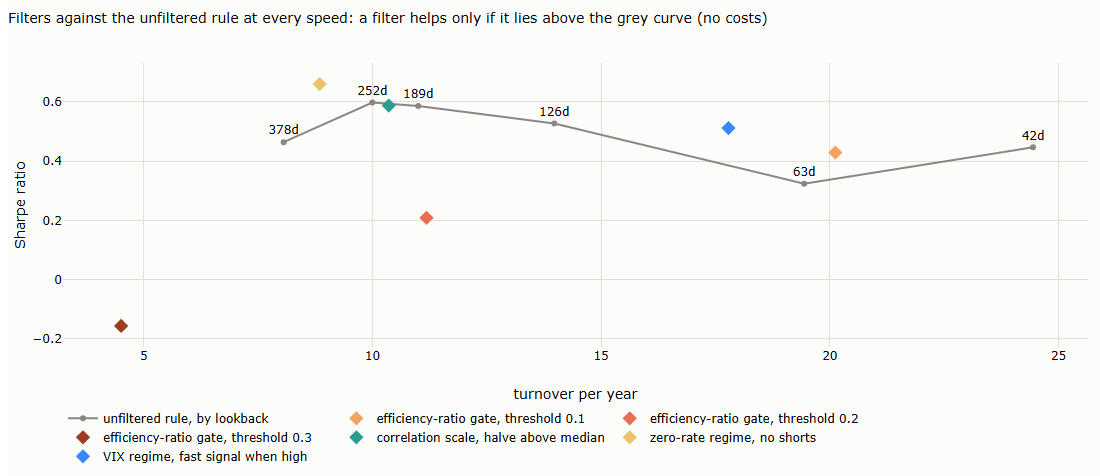

In [5]:
fig = go.Figure()
fig.add_scatter(x=cs["turnover per year"], y=cs["Sharpe, no costs"], mode="lines+markers+text", name="unfiltered rule, by lookback",
                text=[f"{n}d" for n in cs.index], textposition="top center", line=dict(color=MUTED, width=2))
for j, k in enumerate([k for k in table.index if k != "unfiltered 12-month rule"]):
    fig.add_scatter(x=[table.loc[k, "turnover per year"]], y=[table.loc[k, "Sharpe, no costs"]], mode="markers", name=k,
                    marker=dict(size=11, color=["#f4a261", "#e76f51", "#9c3d1f", "#2a9d8f", "#e9c46a", "#3a86ff"][j], symbol="diamond"))
fig.update_layout(title="Filters against the unfiltered rule at every speed: a filter helps only if it lies above the grey curve (no costs)",
                  xaxis_title="turnover per year", yaxis_title="Sharpe ratio", height=500, width=1100, margin=dict(t=80),
                  legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "08_01_filters_vs_curve", FIG)
fig

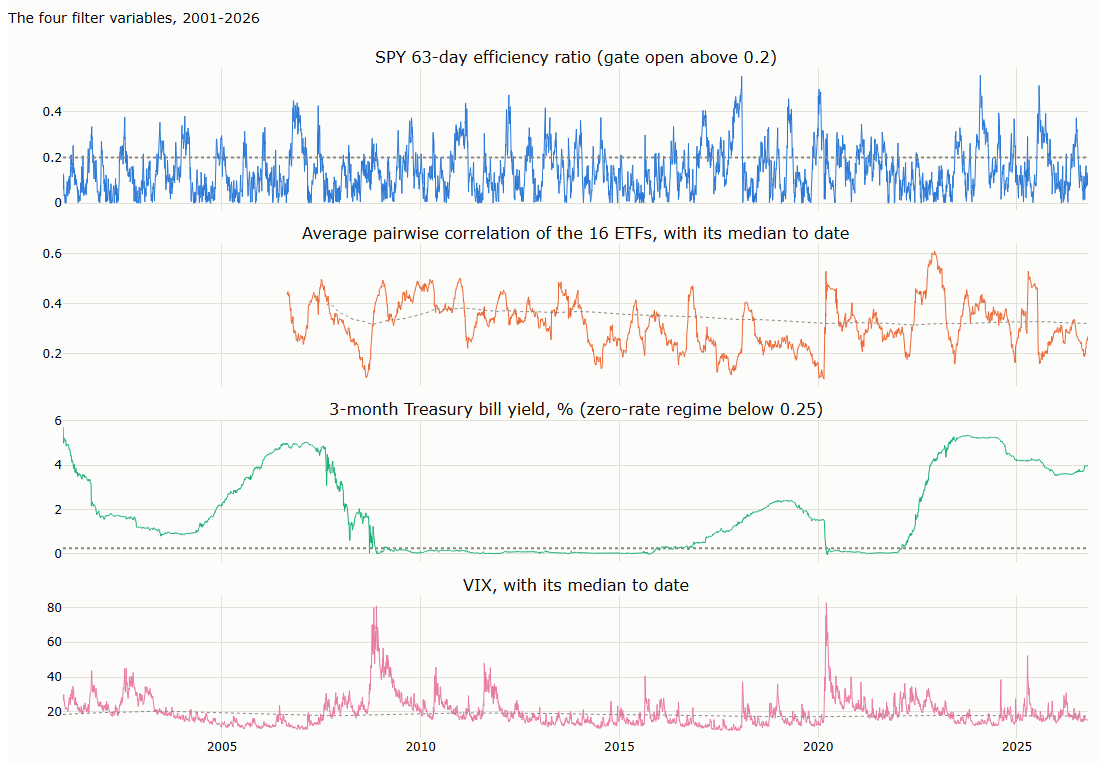

In [6]:
fig = make_subplots(rows=4, cols=1, shared_xaxes=True, vertical_spacing=0.05,
                    subplot_titles=("SPY 63-day efficiency ratio (gate open above 0.2)", "Average pairwise correlation of the 16 ETFs, with its median to date",
                                    "3-month Treasury bill yield, % (zero-rate regime below 0.25)", "VIX, with its median to date"))
s_ = slice(START, None)
fig.add_scatter(x=er["SPY"].loc[s_].index, y=er["SPY"].loc[s_], mode="lines", line=dict(width=1, color=SERIES[0]), showlegend=False, row=1, col=1)
fig.add_hline(y=0.2, line=dict(color=MUTED, dash="dot"), row=1, col=1)
fig.add_scatter(x=avg_rho.loc[s_].index, y=avg_rho.loc[s_], mode="lines", line=dict(width=1, color=SERIES[1]), showlegend=False, row=2, col=1)
fig.add_scatter(x=rho_med.loc[s_].index, y=rho_med.loc[s_], mode="lines", line=dict(width=1, color=MUTED, dash="dot"), showlegend=False, row=2, col=1)
fig.add_scatter(x=tbill.loc[s_].index, y=tbill.loc[s_], mode="lines", line=dict(width=1, color=SERIES[2]), showlegend=False, row=3, col=1)
fig.add_hline(y=0.25, line=dict(color=MUTED, dash="dot"), row=3, col=1)
fig.add_scatter(x=vix.loc[s_].index, y=vix.loc[s_], mode="lines", line=dict(width=1, color=SERIES[3]), showlegend=False, row=4, col=1)
fig.add_scatter(x=vix_med.loc[s_].index, y=vix_med.loc[s_], mode="lines", line=dict(width=1, color=MUTED, dash="dot"), showlegend=False, row=4, col=1)
fig.update_layout(title="The four filter variables, 2001-2026", height=800, width=1100, margin=dict(t=90))
save_figure(fig, "08_02_filter_variables", FIG)
fig